In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the cleaned dataset
df = pd.read_csv("../data/student-por-clean.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
# Select numerical features to predict G3 (excluding G3 itself)
X = df.select_dtypes(include=[np.number]).drop(columns=["G3"])
y = df["G3"]

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set: {X_test.shape[0]} rows")

Training set: 519 rows
Testing set: 130 rows


In [3]:
# Baseline: Always predict the mean G3 value from the training set (with float precision)
baseline_pred = np.full(len(y_test), y_train.mean(), dtype=float)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print("--- Baseline Model (Mean Predictor) ---")
print(f"RMSE: {baseline_rmse:.3f}")
print(f"MAE: {baseline_mae:.3f}")
print(f"R2 Score: {baseline_r2:.3f}")

--- Baseline Model (Mean Predictor) ---
RMSE: 3.173
MAE: 2.395
R2 Score: -0.032


In [4]:
# 1. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

# 2. Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

# Summary table of results
results = pd.DataFrame({
    "Model": ["Baseline (Mean)", "Linear Regression", "Random Forest"],
    "RMSE": [baseline_rmse, lr_rmse, rf_rmse],
    "MAE": [baseline_mae, lr_mae, rf_mae],
    "R2 Score": [baseline_r2, lr_r2, rf_r2]
}).set_index("Model")

print(results.round(3))

                    RMSE    MAE  R2 Score
Model                                    
Baseline (Mean)    3.173  2.395    -0.032
Linear Regression  1.166  0.735     0.860
Random Forest      1.272  0.770     0.834


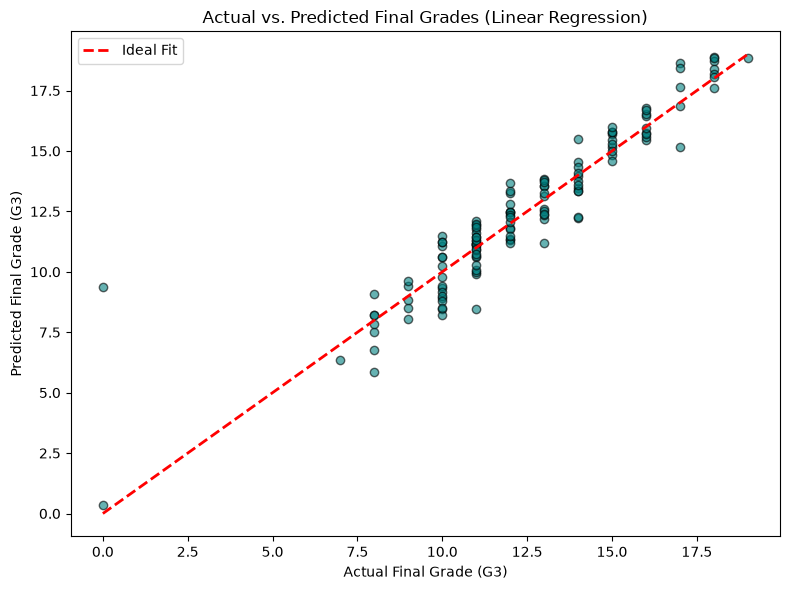

Plot successfully saved to outputs/visualizations/actual_vs_predicted.png


In [5]:
output_dir = Path("../outputs/visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_pred, alpha=0.6, color="teal", edgecolors="k")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2, label="Ideal Fit")

plt.title("Actual vs. Predicted Final Grades (Linear Regression)")
plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade (G3)")
plt.legend()
plt.tight_layout()

plt.savefig(output_dir / "actual_vs_predicted.png", dpi=150)
plt.show()

print("Plot successfully saved to outputs/visualizations/actual_vs_predicted.png")

# Model Evaluation & Error Analysis

Performance Comparison: Both Linear Regression and Random Forest significantly outperform the baseline model, showing strong predictive capability for final grades (G3). Linear Regression yields the lowest RMSE (1.166) and highest R^2 score (0.860), slightly outperforming Random Forest (RMSE = 1.272, R^2 = 0.834) due to strong linear relationships between previous period grades (G1, G2) and the final grade (G3).

Where the Model Makes the Biggest Errors:
1. Extreme Grades and Zero Scores: The model tends to overestimate students who received a 0 for their final grade (G3 = 0), predicting scores around 8–11. 
2. Outliers: Students with unusual performance patterns or sudden changes between G2 and G3 create larger residual errors, as historical averages alone cannot capture sudden academic disruptions.